# Proiectul 1 - Seoul Bike Sharing

ITSchool - Machine Learning

Estimăm numărul de închirieri de biciclete pe oră din calendar, programul serviciului și condițiile meteo. Comparăm regresia liniară și Random Forest cu DummyRegressor.

Date: [Seoul Bike Sharing Demand - UCI](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand), 8.760 observații orare, 14 coloane, licență CC BY 4.0. Ținta este `Rented Bike Count`.

Rulează celulele în ordine. CSV-ul inclus este `SeoulBikeData.csv`; în Colab se descarcă automat dacă lipsește. Vremea din date este observată, iar programul serviciului este presupus cunoscut la estimare.

## 01. Biblioteci și configurație

Importăm bibliotecile pentru date, grafice și modele și fixăm sămânța aleatoare a pădurii. Această configurație permite reproducerea experimentului.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile, BadZipFile
from io import BytesIO
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
SEED = 42
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

## 02. Citirea și verificarea datelor

Citim CSV-ul local sau îl descărcăm din UCI dacă lipsește, apoi verificăm dimensiunea, lipsurile și distribuția țintei. Este o problemă de regresie: estimăm numărul de închirieri dintr-o oră, iar subestimarea poate duce la insuficiența bicicletelor disponibile.

In [ ]:
DATA_PATH = Path("SeoulBikeData.csv")
SOURCE_URL = "https://archive.ics.uci.edu/static/public/560/seoul+bike+sharing+demand.zip"
if not DATA_PATH.is_file():
    print("CSV-ul lipsește local; descarc Seoul Bike Sharing de la UCI...")
    try:
        with urlopen(SOURCE_URL, timeout=30) as response:
            archive_bytes = response.read()
        with ZipFile(BytesIO(archive_bytes)) as archive:
            csv_bytes = archive.read("SeoulBikeData.csv")
        expected_hash = "373339b71a8935d69e9af0abf26a70744632119862eeb3919efb389a7b749c60"
        if hashlib.sha256(csv_bytes).hexdigest() != expected_hash:
            raise ValueError("CSV-ul descărcat diferă de setul verificat.")
        DATA_PATH.write_bytes(csv_bytes)
    except (OSError, BadZipFile, KeyError, ValueError) as error:
        raise RuntimeError("Încarcă SeoulBikeData.csv în sesiunea notebook-ului și rerulează celula.") from error
df = pd.read_csv(DATA_PATH, encoding="latin1")
assert df.shape == (8760, 14)
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df = df.sort_values(["Date", "Hour"]).reset_index(drop=True)
timestamps = df["Date"] + pd.to_timedelta(df["Hour"], unit="h")
assert timestamps.is_unique and timestamps.is_monotonic_increasing
assert df["Rented Bike Count"].notna().all() and df["Rented Bike Count"].ge(0).all()
print("Dimensiune:", df.shape)
print("Interval:", timestamps.min(), "-", timestamps.max())
print("Valori lipsă pe coloane:\n", df.isna().sum().to_string())
print("Distribuția țintei:\n", df["Rented Bike Count"].describe().round(2).to_string())
print("Ore cu zero închirieri:", int(df["Rented Bike Count"].eq(0).sum()))

CSV-ul lipsește local; descarc Seoul Bike Sharing de la UCI...


Dimensiune: (8760, 14)
Interval: 2017-12-01 00:00:00 - 2018-11-30 23:00:00
Valori lipsă pe coloane:
 Date                         0
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Functioning Day              0
Distribuția țintei:
 count    8760.00
mean      704.60
std       645.00
min         0.00
25%       191.00
50%       504.50
75%      1065.25
max      3556.00
Ore cu zero închirieri: 295


## 03. Predictori și împărțire cronologică

Construim ziua săptămânii și folosim primele 80% dintre ore pentru train, ultimele 20% pentru test. Împărțim înainte de imputare și scalare, pentru ca statisticile perioadei de test să nu influențeze învățarea.

In [3]:
df["Weekday"] = df["Date"].dt.dayofweek.astype(str)
df["Hour"] = df["Hour"].astype(str)
y = df["Rented Bike Count"]
X = df.drop(columns=["Rented Bike Count", "Date"])
split_position = int(len(df) * 0.80)
X_train, X_test = X.iloc[:split_position].copy(), X.iloc[split_position:].copy()
y_train, y_test = y.iloc[:split_position].copy(), y.iloc[split_position:].copy()
assert timestamps.iloc[split_position - 1] < timestamps.iloc[split_position]
print(f"Train: {len(y_train)} ore, {timestamps.iloc[0]} - {timestamps.iloc[split_position-1]}")
print(f"Test: {len(y_test)} ore, {timestamps.iloc[split_position]} - {timestamps.iloc[-1]}")
eda = X_train.copy()
eda["Rented Bike Count"] = y_train

Train: 7008 ore, 2017-12-01 00:00:00 - 2018-09-18 23:00:00
Test: 1752 ore, 2018-09-19 00:00:00 - 2018-11-30 23:00:00


## 04. Grafic 1: distribuția cererii

Reprezentăm distribuția numărului de închirieri numai pe train. Observăm dacă există multe ore cu cerere mică și o coadă de valori mari, fără a elimina automat vârfurile.

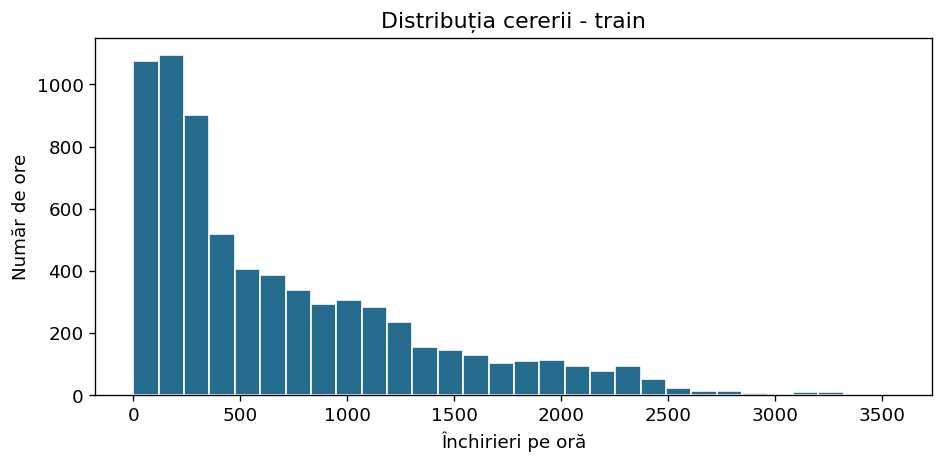

Observație: mediana este 449.0, iar media 691.5 închirieri/oră; distribuția are o coadă spre valori mari.


In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_train, bins=30, color="#246B8E", edgecolor="white")
ax.set(title="Distribuția cererii - train", xlabel="Închirieri pe oră", ylabel="Număr de ore")
fig.tight_layout()
plt.show()
plt.close(fig)
print(f"Observație: mediana este {y_train.median():.1f}, iar media {y_train.mean():.1f} închirieri/oră; distribuția are o coadă spre valori mari.")

## 05. Grafic 2: cererea în funcție de oră

Comparăm cererea medie pe ore între luni-vineri și weekend, folosind train. Acest grafic poate evidenția tipare orare diferite, iar sărbătorile rămân o informație separată în model.

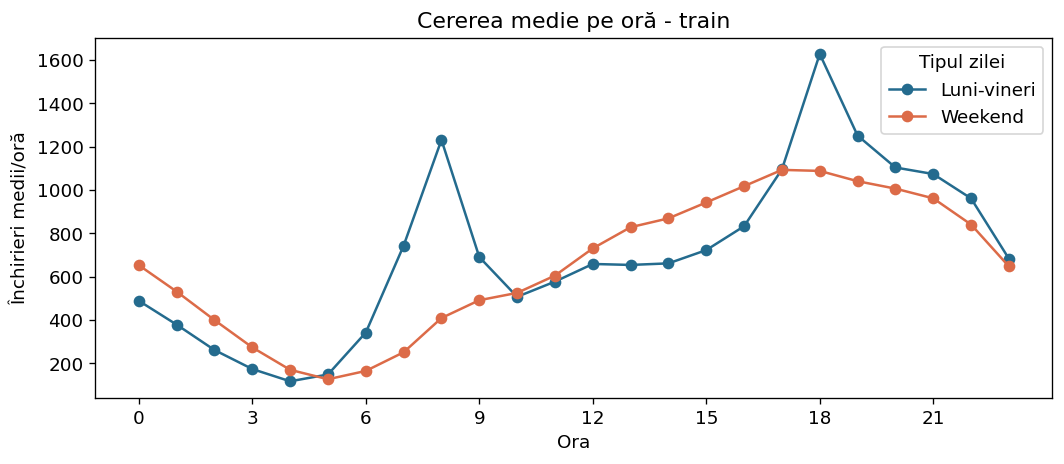

Observație: vârful mediei este la ora 18 luni-vineri și la ora 17 în weekend; tiparul depinde de oră și calendar.


In [5]:
eda["Day group"] = np.where(eda["Weekday"].astype(int) < 5, "Luni-vineri", "Weekend")
hourly_means = eda.groupby(["Hour", "Day group"])["Rented Bike Count"].mean().unstack()
hourly_means.index = hourly_means.index.astype(int)
hourly_means = hourly_means.sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
hourly_means.plot(ax=ax, marker="o", color=["#246B8E", "#DC6B48"])
ax.set(title="Cererea medie pe oră - train", xlabel="Ora", ylabel="Închirieri medii/oră", xticks=list(range(0, 24, 3)))
ax.legend(title="Tipul zilei")
fig.tight_layout()
plt.show()
plt.close(fig)
print(f"Observație: vârful mediei este la ora {hourly_means['Luni-vineri'].idxmax()} luni-vineri și la ora {hourly_means['Weekend'].idxmax()} în weekend; tiparul depinde de oră și calendar.")

## 06. Grafic 3: temperatură și cerere

Reprezentăm relația dintre temperatura observată și cererea de train. Dispersia punctelor arată că temperatura nu explică singură numărul de închirieri.

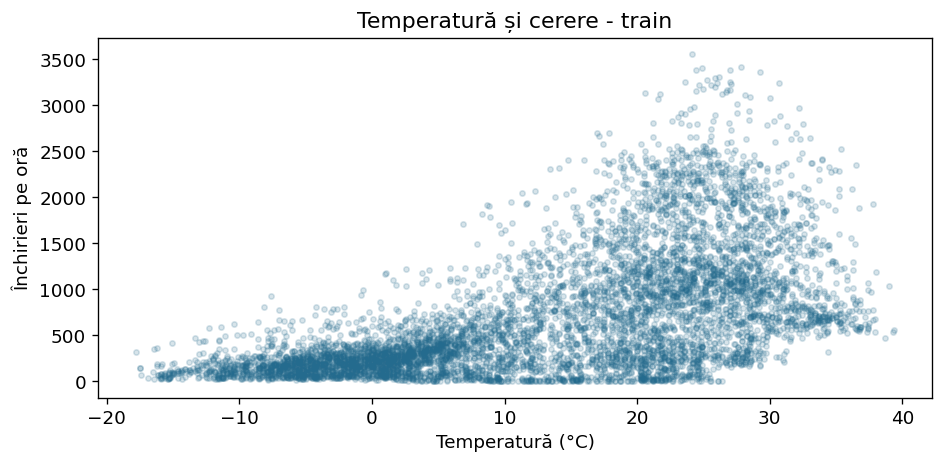

Observație: corelația temperatură-cerere este 0.59, dar la aceeași temperatură există cereri diferite; asocierea nu demonstrează cauzalitate.


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(eda["Temperature(°C)"], y_train, s=10, alpha=0.18, color="#246B8E")
ax.set(title="Temperatură și cerere - train", xlabel="Temperatură (°C)", ylabel="Închirieri pe oră")
fig.tight_layout()
plt.show()
plt.close(fig)
temperature_correlation = eda["Temperature(°C)"].corr(y_train)
print(f"Observație: corelația temperatură-cerere este {temperature_correlation:.2f}, dar la aceeași temperatură există cereri diferite; asocierea nu demonstrează cauzalitate.")

## 07. Preprocesare, baseline și două modele

Pipeline-ul învață completarea lipsurilor și codificarea categoriilor numai pe train; standardizăm numerele pentru modelul liniar, deși scalarea nu este obligatorie pentru OLS. Comparăm baseline-ul mediană cu regresia liniară și Random Forest.

In [7]:
categorical_columns = ["Hour", "Weekday", "Seasons", "Holiday", "Functioning Day"]
numeric_columns = X.select_dtypes(include="number").columns.tolist()
assert set(numeric_columns + categorical_columns) == set(X.columns)
def make_preprocessor(scale):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))
    category_steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
    ]
    return ColumnTransformer([
        ("num", Pipeline(numeric_steps), numeric_columns),
        ("cat", Pipeline(category_steps), categorical_columns)
    ])
models = {
    "DummyRegressor": Pipeline([
        ("preprocessor", make_preprocessor(False)),
        ("model", DummyRegressor(strategy="median"))
    ]),
    "Regresie liniară": Pipeline([
        ("preprocessor", make_preprocessor(True)),
        ("model", LinearRegression())
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", make_preprocessor(False)),
        ("model", RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=2, random_state=SEED, n_jobs=1))
    ])
}

## 08. Antrenare și evaluare

Antrenăm toate configurațiile pe același train și calculăm MAE, RMSE și R² pe același test, fără ajustări după rezultate. Alegem MAE ca metrică principală pentru interpretarea directă a erorii în închirieri pe oră și limităm estimările la minimum zero pentru toate modelele.

In [8]:
rows = []
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    raw_prediction = pipeline.predict(X_test)
    prediction = np.clip(raw_prediction, 0, None)
    rows.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
        "R2": r2_score(y_test, prediction)
    })
metrics = pd.DataFrame(rows).set_index("model")
display(metrics.round(3))
print("Versiuni:", "scikit-learn", sklearn.__version__, "pandas", pd.__version__, "numpy", np.__version__)

,MAE,RMSE,R2
model,,,
DummyRegressor,537.263,686.323,-0.252
Regresie liniară,235.137,327.385,0.715
Random Forest,308.349,435.283,0.496


Versiuni: scikit-learn 1.7.2 pandas 2.2.3 numpy 2.3.5


## 09. Concluzie calculată din rezultate

Calculăm automat recomandarea și reducerea erorii față de baseline, folosind rezultatele acestei rulări. Concluzia precizează limitele unei comparații pe un singur test temporal, cu vreme observată.

In [9]:
recommended_name = metrics.loc[["Regresie liniară", "Random Forest"], "MAE"].idxmin()
recommended = metrics.loc[recommended_name]
baseline = metrics.loc["DummyRegressor"]
mae_gain = baseline["MAE"] - recommended["MAE"]
mae_gain_percent = mae_gain / baseline["MAE"] * 100
linear = metrics.loc["Regresie liniară"]
forest = metrics.loc["Random Forest"]
if recommended_name == "Regresie liniară":
    interpretation = "Forma aditivă a modelului liniar poate generaliza mai bine pe această perioadă; complexitatea pădurii nu garantează transferul către un test cu altă compoziție."
else:
    interpretation = "Pădurea poate surprinde praguri și interacțiuni pe care forma aditivă a modelului liniar le reprezintă mai greu."
conclusion = f"""### Rezultate și recomandare

DummyRegressor prezice mediana train ({y_train.median():.1f} închirieri/oră): MAE **{baseline['MAE']:.2f}**, RMSE **{baseline['RMSE']:.2f}**, R² **{baseline['R2']:.3f}**.

Regresia liniară are MAE **{linear['MAE']:.2f}**, iar Random Forest are MAE **{forest['MAE']:.2f}**. Recomandarea în această comparație este **{recommended_name}**, cu MAE **{recommended['MAE']:.2f}**, RMSE **{recommended['RMSE']:.2f}** și R² **{recommended['R2']:.3f}**.

Față de baseline, MAE scade cu **{mae_gain:.2f} închirieri/oră**, adică **{mae_gain_percent:.2f}%**. {interpretation} Aceasta este o explicație plauzibilă, nu o demonstrație cauzală.

**Limitări:** un singur an și un singur test de toamnă, fără evaluare independentă după alegerea modelului. Folosim vremea observată și presupunem programul serviciului cunoscut; o prognoză reală ar avea nevoie și de prognoze meteo. Subestimarea poate duce la insuficiența bicicletelor disponibile, dar datele nu conțin costuri comerciale sau stații individuale.
"""
display(Markdown(conclusion))

### Rezultate și recomandare

DummyRegressor prezice mediana train (449.0 închirieri/oră): MAE **537.26**, RMSE **686.32**, R² **-0.252**.

Regresia liniară are MAE **235.14**, iar Random Forest are MAE **308.35**. Recomandarea în această comparație este **Regresie liniară**, cu MAE **235.14**, RMSE **327.38** și R² **0.715**.

Față de baseline, MAE scade cu **302.13 închirieri/oră**, adică **56.23%**. Forma aditivă a modelului liniar poate generaliza mai bine pe această perioadă; complexitatea pădurii nu garantează transferul către un test cu altă compoziție. Aceasta este o explicație plauzibilă, nu o demonstrație cauzală.

**Limitări:** un singur an și un singur test de toamnă, fără evaluare independentă după alegerea modelului. Folosim vremea observată și presupunem programul serviciului cunoscut; o prognoză reală ar avea nevoie și de prognoze meteo. Subestimarea poate duce la insuficiența bicicletelor disponibile, dar datele nu conțin costuri comerciale sau stații individuale.
